In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)


In [2]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA = "tnp_sample"   # change to "tnp" when the full conversion is done

spark = (SparkSession.builder.appName("trip-eda")
         .config("spark.driver.memory", "1g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df = spark.read.parquet(str(ROOT / "data" / "parquet" / DATA))

for c in ["trip_seconds", "trip_miles", "fare"]:
    df = df.withColumn(c, F.col(c).cast("double"))
df = df.withColumn("pickup_area", F.col("pickup_community_area").cast("int"))

# cleaning rules from the data-quality notebook
df = df.filter((F.col("trip_seconds") > 0) & (F.col("trip_miles") > 0)
               & (F.col("trip_seconds") <= 4 * 3600) & (F.col("trip_miles") <= 100))

df = df.withColumn("hour", F.hour("trip_start_timestamp")) \
       .withColumn("dow", F.dayofweek("trip_start_timestamp"))   # 1 = Sunday

print(df.count())


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/28 22:01:55 WARN Utils: Your hostname, Dharmiks-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 10.0.0.246 instead (on interface en0)
26/10/28 22:01:55 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 22:01:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


199878


m = df.groupBy(F.date_trunc("month", "trip_start_timestamp").alias("month")).count() \
      .orderBy("month").toPandas()
m.plot(x="month", y="count", figsize=(10, 4), legend=False, marker="o",
       title="Rideshare trips per month")
plt.ylabel("Trips"); plt.show()

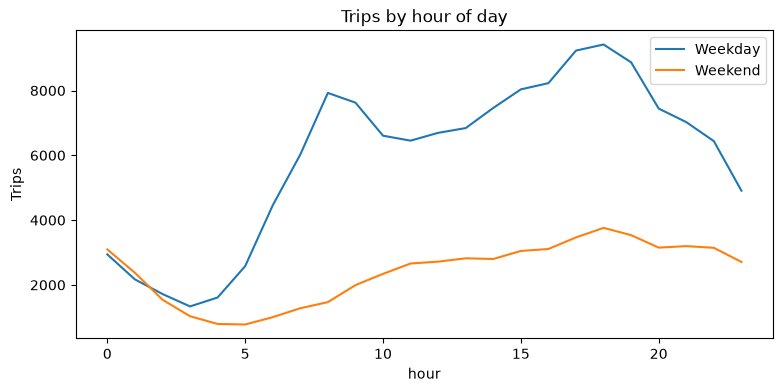

In [9]:
h = df.withColumn("weekend", F.col("dow").isin(1, 7)) \
      .groupBy("hour", "weekend").count().toPandas() \
      .pivot(index="hour", columns="weekend", values="count").sort_index()
h.columns = ["Weekday" if not c else "Weekend" for c in h.columns]
h.plot(figsize=(9, 4), title="Trips by hour of day")
plt.ylabel("Trips"); plt.show()

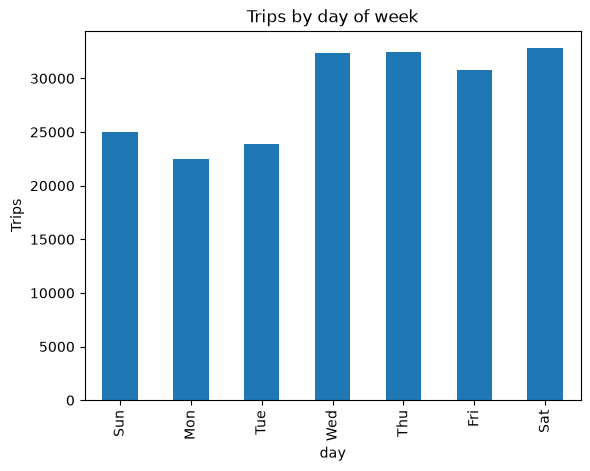

In [10]:
d = df.groupBy("dow").count().orderBy("dow").toPandas()
d["day"] = d["dow"].map({1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"})
d.plot(kind="bar", x="day", y="count", legend=False, title="Trips by day of week")
plt.ylabel("Trips"); plt.show()

In [14]:
FRAC = 0.2 if DATA == "tnp_sample" else 0.01   # use more of the sample, less of the full data

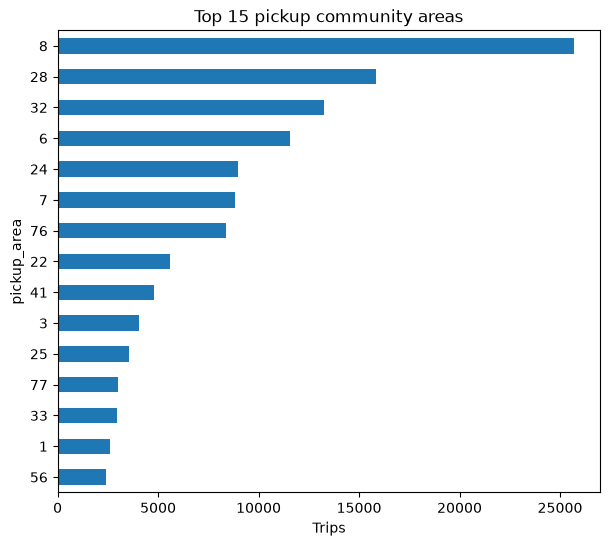

In [12]:
a = df.filter(F.col("pickup_area").isNotNull()).groupBy("pickup_area").count() \
      .orderBy(F.desc("count")).limit(15).toPandas()
a["pickup_area"] = a["pickup_area"].astype(str)
a.plot(kind="barh", x="pickup_area", y="count", legend=False, figsize=(7, 6),
       title="Top 15 pickup community areas")
plt.xlabel("Trips"); plt.gca().invert_yaxis(); plt.show()


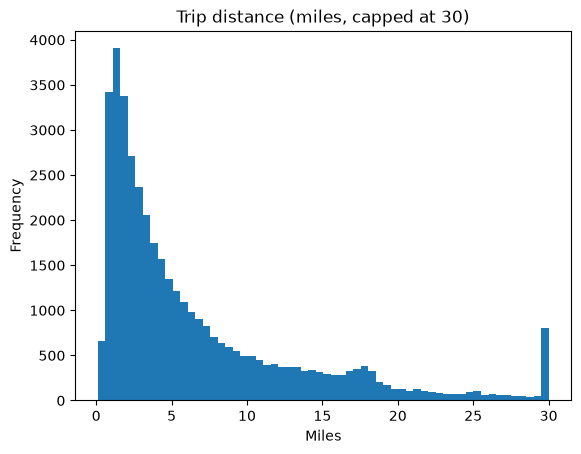

In [15]:
dist = df.select(F.least(F.col("trip_miles"), F.lit(30)).alias("miles")) \
         .sample(FRAC, seed=1).toPandas()
dist["miles"].plot(kind="hist", bins=60, title="Trip distance (miles, capped at 30)")
plt.xlabel("Miles"); plt.show()

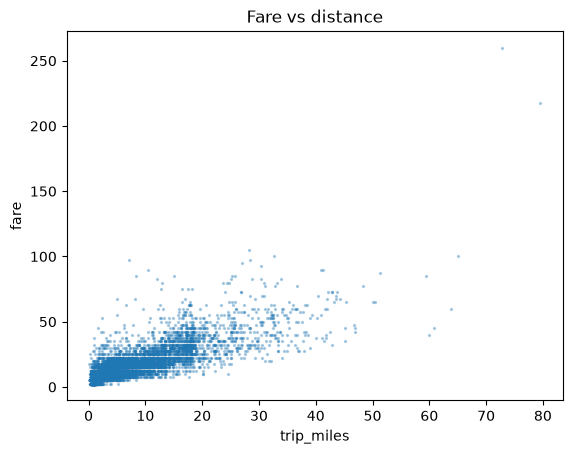

In [16]:
fd = df.filter(F.col("fare") > 0).select("trip_miles", "fare") \
       .sample(FRAC / 5, seed=1).toPandas()
fd.plot(kind="scatter", x="trip_miles", y="fare", s=2, alpha=0.3,
        title="Fare vs distance")
plt.show()